##### Master Degree in Computer Science and Data Science for Economics and Health

# From a pre-trained model to an assistant: prompts, instruction tuning, RLHF and DPO

### Prof. Alfio Ferrara

## Introduction

A pre-trained language model *continues* a text. If we write a question it does not answer it: it writes what could come after a question in the texts that it has seen, and that can be another question. To get an assistant we need to change what the model does with the text that we give it. This notebook goes through the ways to do it, from the cheapest to the most expensive, and it does so on a toy where we can read every answer and decide, without ambiguity, which one is right.

The questions of this notebook:

1. **Step 1**: the problem. The network of the previous notebooks, pre-trained on the documents of a small world, is given an *instruction*. We see what it does;
2. **Step 2**: prompt engineering, in few words and without code: what we can obtain without changing a single weight, and where it stops;
3. **Step 3**: instruction tuning, that is, fine-tuning (with the LoRA of L1.5) on pairs *(instruction, response)*. We test it on instructions that the network has not seen in the fine-tuning, and we see what the variety of the instructions changes;
4. **Step 4**: preferences. Often we cannot write the right response, but we can say which of two is better. We collect pairs (chosen, rejected) and we train a **reward model** that gives a score to a response;
5. **Step 5**: RLHF. The network writes responses, the reward model scores them, and the network is trained to write the ones that score high, with a penalty for going too far from where it started. We look for what happens when the score is the only thing that counts;
6. **Step 6**: DPO. The same preferences, without a reward model and without writing text during the training. We compare it with Step 5;
7. **Step 7**: what we did not do, who decides what is better (a bridge to L1.9, bias), and the conclusions.

The networks that take time to train are saved **outside the repository**, in `models/L1.6/` (the function `trained_network` below): if the file is there the network is loaded, otherwise it is trained and saved. If you change the data, the settings or `tinylm.py`, delete the folder.

As in the previous notebooks, the toy world has its advantages (we can read everything and train in seconds) and its limits: our network has 60,000 parameters, the "people" of our world are twelve names, and the "annotator" that says which response is better is a rule that we write, not a person. We say it each time it matters, and the last step collects the limits.

In [1]:
import os
import re
import copy
import time
import inspect
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from nlp import toyworld, tinylm

warnings.filterwarnings("ignore", category=FutureWarning)

CACHE = "../../models/L1.6"                  # outside the repository: the trained networks, saved only to save time

def trained_network(name, train):
    # the network saved under `name` in CACHE if the file exists; otherwise `train()` trains it and it is saved there
    start = time.time()
    model, loaded = tinylm.cached(f"{CACHE}/{re.sub('[^a-z0-9]+', '-', name.lower()).strip('-')}.pt", train)
    print(f"{name}: {model.n_parameters():,} parameters, " + ("loaded from the cache" if loaded else f"trained in {time.time() - start:.0f} s"))
    return model

## Step 1: from the base network to an assistant

> **A simple example.** In L1.5 we gave the network a pair of sentences, `anna lives in milan . <sep>`, and it continued with a translation. Now we give it an *instruction*: `full lang-a marco drink <sep>`, which in our toy means *write the fact about Marco's drink, as a complete sentence, in language A*. The right answer is `marco drinks tea .` (if Marco drinks tea in our world). What do we expect from a network that has only read the documents of the world?
>
> The question of this section is: does a pre-trained network follow an instruction? The intuition is that it knows the facts (it has seen them many times) and it knows the three languages, but nobody has told it that the text before `<sep>` is a request and the text after is an answer to it: it will continue the text with something that *looks like* the texts that it knows.

In [2]:
LANGUAGE_B, LANGUAGE_C = toyworld.make_language_b(0), toyworld.make_language_b(7)     # two other languages, same word order, other words
world = toyworld.ToyWorld(toyworld.WorldConfig(n_people=12, seed=0), language_b=LANGUAGE_B, extra_languages={"C": LANGUAGE_C})

FORMATS, LANGUAGES, RELATIONS = ["full", "value", "pron"], ["a", "b", "c"], ["drink", "job", "city", "color"]
INSTRUCTION_WORDS = FORMATS + [f"lang-{l}" for l in LANGUAGES] + RELATIONS         # the words of the instructions: new for the network
vocab = world.vocabulary(("A", "B", "C"), extra=INSTRUCTION_WORDS)
SEP, EOS = vocab.encode(["<sep>"])[0], 2
ITEMS = [(person, relation) for person in world.people for relation in RELATIONS]  # 48 facts: what the network can be asked
print(f"{len(vocab)} words in the vocabulary, {len(ITEMS)} facts in the world\n")
print(pd.DataFrame(world.table()).head(4).to_string(index=False))

127 words in the vocabulary, 48 facts in the world

person gender  drink      job   city  color
  anna      f  cocoa   farmer  milan    red
 marco      m coffee    nurse naples  brown
  luca      m  juice mechanic naples yellow
  sara      f  juice    clerk  genoa    red


**The world and the instructions.** There is one world, with twelve people and four facts for each (drink, job, city, favourite colour): 48 facts. The network will know them because it reads many documents about them, and it will not read any other world. An **instruction** has four words, `format language person relation`, and the response depends on the first two:

| format | response, for `marco drink` (if Marco drinks tea) |
|---|---|
| `full` | the complete sentence: `marco drinks tea .` |
| `value` | only the value: `tea .` |
| `pron` | the sentence with the pronoun instead of the name: `he drinks tea .` |

and the language (`lang-a`, `lang-b`, `lang-c`) is the language in which the response is written, so there are $3 \times 3 = 9$ different instructions (we call them *types*, to tell them from the single request). The words `full`, `value`, `pron`, `lang-a` and so on are **new** words for the network: the pre-training never contains them, as the documents of the world do not contain instructions. An instruction followed by its response is written as in L1.4 and L1.5: `<s> instruction <sep> response </s>`.

In [3]:
def respond(fmt, lang, person, relation):
    # the right response to an instruction: the fact of the world written in the format and in the language requested
    fact, L = world.fact(person, relation), lang.upper()
    if fmt == "full":
        return world.say(fact, L)
    if fmt == "pron":
        return world.say(fact, L, pronoun=True)
    value = fact[2] if L == "A" else world.language[L]["lexicon"].get(fact[2], fact[2])
    return [value, "."]

def instruction(fmt, lang, person, relation):
    return ["<s>", fmt, f"lang-{lang}", person, relation, "<sep>"]

def request(fmt, lang, person, relation):
    # instruction and right response: the text of one example
    return instruction(fmt, lang, person, relation) + respond(fmt, lang, person, relation) + ["</s>"]

def as_tensor(texts, length=40):
    t = torch.tensor(vocab.batch(texts))
    return F.pad(t, (0, length - t.shape[1]))

def documents(language, n, seed):
    return world.documents(seed, n, language=language)

print(" ".join(request("full", "a", "marco", "drink")))
print(" ".join(request("value", "b", "marco", "drink")))
print(" ".join(request("pron", "c", "marco", "drink")))

<s> full lang-a marco drink <sep> marco drinks coffee . </s>
<s> value lang-b marco drink <sep> torge . </s>
<s> pron lang-c marco drink <sep> zinfi zosvis lulpir . </s>


**The base network.** It is the decoder-only network of L1.4 and L1.5 (4 blocks, $d = 32$, 2 heads), pre-trained with the usual loss, the next word at every position, on 30,000 documents of the world: 10,000 in each of the three languages. Two seeds.

In [4]:
pretraining = torch.cat([as_tensor(documents(language, 10000, 100 + i)) for i, language in enumerate("ABC")])
print(pretraining.shape[0], "documents of", pretraining.shape[1], "positions")

def pretrain(seed):
    return tinylm.fit_lm(pretraining, seed=seed, steps=4000, batch_size=64, model_class=tinylm.DecoderOnly, vocabulary_size=len(vocab), sep=SEP)

SEEDS = (0, 1)
bases = [trained_network(f"base seed {s}", lambda s=s: pretrain(s)) for s in SEEDS]

30000 documents of 40 positions
base seed 0: 60,671 parameters, loaded from the cache
base seed 1: 60,671 parameters, loaded from the cache


In [5]:
plain = as_tensor(documents("A", 500, 900))
print("loss on plain documents of the world (the usual next-word loss):", [round(tinylm.lm_loss(b, plain), 2) for b in bases])

for fmt, lang in [("full", "a"), ("value", "b"), ("pron", "c")]:
    prompt = as_tensor([instruction(fmt, lang, "marco", "drink")])[:, :6]
    written = tinylm.complete(bases[0], F.pad(prompt, (0, 34)), SEP)[0]
    print("\nasked    :", " ".join(vocab.decode(prompt[0].tolist())))
    print("expected :", " ".join(respond(fmt, lang, "marco", "drink")))
    print("written  :", " ".join(vocab.decode(written[6:].tolist(), skip_special=True)))

loss on plain documents of the world (the usual next-word loss): [0.53, 0.53]

asked    : <s> full lang-a marco drink <sep>
expected : marco drinks coffee .
written  : zuszu tunrus . kesva duzul pumus . kungos duzul luca . pumus zuszu tunrus . vaszan pumus vudas .

asked    : <s> value lang-b marco drink <sep>
expected : torge .
written  : duzul pumus . pumus torge dinsos . giulia zuszu toslu . lirzar lirnes vudas . bantis duzul lirnes .

asked    : <s> pron lang-c marco drink <sep>
expected : zinfi zosvis lulpir .
written  : zuszu goslil . nespen duzul pumus . carlo zuszu goslil . nespen duzul pumus . pumus nunto dinsos .


The base network does not follow any of the three instructions, and in the three cases (seed 0) it does the same thing: it writes a text made of sentences in language B, with the names of other people, as it would continue a document. It does not answer the question about Marco, and it does not even use the language that we asked for (language A in the first case, language C in the third). The loss on plain documents (0.53 for both seeds) is the reference for what the network can do when it is asked what it was trained for: continue a text.

What the network is missing is not knowledge. It has seen every fact of this world many times, in three languages, and the instruction tuning of Step 3 will need only 1,000 examples (against the 30,000 documents of the pre-training). What is missing is the *behavior*: that after `<sep>` it must write the answer to the instruction. This is what this notebook is about, and the cheapest ways to get it come first.

## Step 2: prompt engineering, in short

> **A simple example.** We cannot change the network, but we can change what we write before the question. Instead of `full lang-a marco drink <sep>` we write two *examples* of the task and then the question: `<s> full lang-a anna city <sep> anna lives in rome . </s> <s> full lang-a luca job <sep> luca is a baker . </s> <s> full lang-a marco drink <sep>`. The network does not have to know the word `full`: it can see from the two examples what the task is, and do the same thing for the third.
>
> The question of this section is: how far can we go by writing the right text, with the weights untouched? The intuition is that a network that has seen many different tasks in its pre-training can recognize one from a few examples, and that a network that has seen only one kind of text cannot.

This step has no code: what we have to say is short, and the experiments that this notebook needs are in the other steps. **Prompt engineering** is the set of techniques that change the *text* given to the model, and not the model:

* **Zero-shot and instructions in words.** We describe the task in the prompt. It works only if the model has seen, in its training, texts in which such a description is followed by the right behavior: it is the case of the assistants, because they have been trained for it (Step 3), and it is not the case of our base network, as Step 1 has shown;
* **Few-shot, or in-context learning.** We give a few examples of the task in the prompt, as above. We have measured this in L1.4: a network trained on many different assignments of symbols to sentences got better with the number of examples in the prompt on assignments that it had never seen (from 0.07 with no example to 0.96 with eight), while a network trained on only three assignments *learned them* and did not generalize (0.27-0.34 on the new ones). Two lessons that come back below: the behavior is a property of the **training data**, and **variety** is what makes it work;
* **Chain of thought** (Wei et al., 2022): the examples in the prompt (or the instruction) ask the model to write the intermediate steps before the answer, and the answer is written *after* them, so the network can read them. We do not test it here: our toy answers are one sentence, with no steps to write;
* **Retrieval-augmented generation, RAG** (Lewis et al., 2020): a system looks for the documents that are relevant for a question, and puts them in the prompt, so that the answer can be read in the context and does not have to be remembered in the weights. It connects with what we saw in L1.2 and L1.3: a network that learned the facts of *one* world in its weights does not read them from a new world. Here too we only describe it.

What these techniques have in common is their cost (nothing to train, a longer text) and their limit: they use what the model already knows how to do. When the behavior we want is not there, we have to change the weights.

## Step 3: instruction tuning

> **A simple example.** We show the network 1,000 pairs *(instruction, response)*, for example `full lang-a marco drink` → `marco drinks tea .` and `value lang-b anna city` → `(the city of Anna, in B) .`, and we train it with the loss of L1.5 (only on the words after `<sep>`), changing only the LoRA adapter. After this the network should answer the instructions that we have shown.
>
> The question of this section is: does the network follow *only* the instructions that it has seen, or also new ones? The intuition is that the network that has seen few types of instruction learns them as separate recipes, as the network of L1.4 learned the three assignments, and that the more types it sees, the more the words of the instruction (`value`, `lang-c`) become pieces that can be combined: with `value` seen in one language and `lang-c` seen with another format, the network could write the value in language C without ever having seen it.

**Instruction tuning** (or *supervised fine-tuning*, SFT) is the fine-tuning of Step 2 of L1.5 where the examples are pairs *(instruction, response)* written by someone: nothing new in the method, everything new in the data (the reference for the use of this step in an assistant is Ouyang et al., 2022). We use LoRA ($r = 8$, attention and MLP, learning rate $10^{-2}$, 1,000 steps, the settings of L1.5).

The experiment keeps the number of examples fixed (1,000) and changes the number of *types* of instruction in them. Two types are **held out**, they never appear in the fine-tuning: `value lang-c` and `pron lang-b`. The order in which the types enter is chosen so that every new word (`full`, `value`, `pron`, `lang-a`, `lang-b`, `lang-c`) appears in at least one type from the first three: `full lang-a`, `value lang-b`, `pron lang-c`. Then `full lang-b`, `value lang-a` (five types), `full lang-c` and `pron lang-a` (seven types). The test is on the facts of the world, all 48, written in the format and language that were held out: the network has the knowledge (it comes from the pre-training), and what it has to do is only to follow the instruction.

In [6]:
ORDER = [("full", "a"), ("value", "b"), ("pron", "c"), ("full", "b"), ("value", "a"), ("full", "c"), ("pron", "a")]
HELD_OUT = [("value", "c"), ("pron", "b")]

def instruction_examples(types, n, seed):
    rng = np.random.default_rng(seed)
    return as_tensor([request(*types[rng.integers(len(types))], *ITEMS[rng.integers(len(ITEMS))]) for _ in range(n)])

def all_requests(types):
    return as_tensor([request(fmt, lang, person, relation) for fmt, lang in types for person, relation in ITEMS])

def instruction_network(k, seed):
    def train():
        model = tinylm.add_lora(copy.deepcopy(bases[seed]), 8, ("attention", "mlp"), seed=seed)
        return tinylm.fine_tune(model, instruction_examples(ORDER[:k], 1000, 10 + seed), SEP, steps=1000, lr=1e-2, seed=seed)
    return trained_network(f"instruction tuning {k} types seed {seed}", train)

instruction_nets = {(k, s): instruction_network(k, s) for k in (3, 5, 7) for s in SEEDS}

instruction tuning 3 types seed 0: 78,079 parameters, loaded from the cache
instruction tuning 3 types seed 1: 78,079 parameters, loaded from the cache
instruction tuning 5 types seed 0: 78,079 parameters, loaded from the cache
instruction tuning 5 types seed 1: 78,079 parameters, loaded from the cache
instruction tuning 7 types seed 0: 78,079 parameters, loaded from the cache
instruction tuning 7 types seed 1: 78,079 parameters, loaded from the cache


In [7]:
def accuracy(model, types):
    # sentences exactly right and words right at the right place, for the instructions of the given types (mean over the types)
    results = [tinylm.completion_accuracy(model, all_requests([t]), SEP) for t in types]
    return np.mean([r[0] for r in results]), np.mean([r[1] for r in results])

rows = []
for k in (0, 3, 5, 7):
    per_seed = []
    for s in SEEDS:
        model = bases[s] if k == 0 else instruction_nets[(k, s)]
        per_seed.append({"seen": accuracy(model, ORDER[:k])[0] if k else np.nan, "held-out sentences": accuracy(model, HELD_OUT)[0], "held-out words": accuracy(model, HELD_OUT)[1]})
    table = pd.DataFrame(per_seed)
    rows.append({"types in the fine-tuning": k, "instructions seen: sentences": table["seen"].mean(), "held-out: sentences": table["held-out sentences"].mean(),
                 "held-out: words": table["held-out words"].mean(), "held-out words, seed 0 / seed 1": " / ".join(f"{x:.2f}" for x in table["held-out words"])})
pd.DataFrame(rows).style.format({"instructions seen: sentences": "{:.3f}", "held-out: sentences": "{:.3f}", "held-out: words": "{:.3f}"}, na_rep="").hide(axis="index")

types in the fine-tuning,instructions seen: sentences,held-out: sentences,held-out: words,"held-out words, seed 0 / seed 1"
0,,0.000,0.004,0.01 / 0.00
3,1.000,0.005,0.144,0.10 / 0.19
5,0.994,0.021,0.539,0.59 / 0.49
7,1.000,0.047,0.601,0.68 / 0.52


In [8]:
model = instruction_nets[(7, 0)]
for t in HELD_OUT:
    asked = all_requests([t])
    written = tinylm.complete(model, asked[[0, 17, 30]], SEP)
    for row, text in zip(asked[[0, 17, 30]], written):
        print("asked    :", " ".join(vocab.decode(row[:6].tolist())))
        print("expected :", " ".join(vocab.decode(row[6:].tolist(), skip_special=True)))
        print("written  :", " ".join(vocab.decode(text[6:].tolist(), skip_special=True)), "\n")

asked    : <s> value lang-c anna drink <sep>
expected : pirzus .
written  : coffee . 

asked    : <s> value lang-c giulia job <sep>
expected : muri .
written  : farmer . 

asked    : <s> value lang-c diego city <sep>
expected : tulpir .
written  : naples . 

asked    : <s> pron lang-b anna drink <sep>
expected : lirnes tavar dinsos .
written  : dinsos . sunna tavar 

asked    : <s> pron lang-b giulia job <sep>
expected : lirzar lirnes vudas .
written  : lirzar giulia vudas . 

asked    : <s> pron lang-b diego city <sep>
expected : pumus zuszu tunrus .
written  : he zuszu tunrus . 



**The instructions that the network has seen are learned: 100% of the sentences exactly right** (1.000, 0.994 and 1.000 with 3, 5 and 7 types, mean of two seeds; the base network gets none of them, and we do not report it in the table because it was never asked to do them). 1,000 examples and an adapter of 17,408 numbers (29% of the network, the same count as in L1.5) are enough to turn a network that writes documents into one that answers.

**The instructions that it has not seen are not followed.** The sentences exactly right on the two held-out types are 0.5%, 2.1% and 4.7% with 3, 5 and 7 types in the fine-tuning: never more than one in twenty. The variety of the types changes only the *words right at the right place*, from 0.144 (3 types; 0.10 and 0.19 in the two seeds) to 0.539 (5 types) and 0.601 (7 types), against 0.004 for the base network. We have to read this number with care. For the held-out type `value lang-c` the response has three positions, the value, the full stop and `</s>`, and the last two do not depend on the language: a network that writes the right *shape* and a wrong word already gets 2/3 = 0.67 of the words. And this is what the examples (seed 0, 7 types) show: for `value lang-c` the network writes a single word and the full stop, as a `value` response, but the word is the one of language A (`coffee`, `farmer`, `naples`), not of language C. For `pron lang-b` it writes a sentence of the right shape with words of language B, but it gets the pronoun wrong (`lirzar giulia vudas .`, the name instead of the pronoun; `he zuszu tunrus .`, the pronoun of language A) or mixes the order. So the network has learned that `value` means a single word and that `pron` means a pronoun, but not how these combine with a language it has seen only with other formats.

What we can conclude, and what not. With few types (3) the network does not even get the shape of the held-out response; with 5 or 7 it does, and the content is not there yet. The two seeds agree on the direction and differ by 0.09-0.16 in the words (0.59 and 0.49 with 5 types, 0.68 and 0.52 with 7). The hope that the pieces `value` and `lang-c` would be combined is **not confirmed** in our toy, in the sentences, and only the shape is. We did not try more types, more examples or a different choice of the held-out types, so we do not know whether they would change the picture; the comparison with the in-context learning of L1.4 (a network trained on 18 assignments did better on new ones, on 3 it did not) says that the variety of the training is the thing to change, but here it has not been enough.

## Step 4: preferences and the reward model

> **A simple example.** Instruction tuning needs the right response for each instruction. Often there is not *one* right response, or it is easier to *compare* two responses than to write one. For the instruction `full lang-a marco drink` suppose that the network writes two responses: (1) `marco drinks tea .` and (2) `marco drinks milk . marco lives in rome .`. Marco drinks tea: the first is right, the second is wrong but longer. A person who reads both says "the first is better". We do not write a response: we only record the choice, as a triple *(instruction, chosen response, rejected response)*.
>
> The question of this section is: can we turn a set of such choices into a **number**, a score that tells how good a response is for an instruction? The intuition is that the choices contain the criterion of the annotator, and that a network that learns to predict the choices has learned the criterion, even if nobody wrote it down.

**The assistant to improve.** From here on we use one instruction, `full lang-a person relation`, and a network that has already been through instruction tuning (as in Step 3), but on demonstrations of **mixed quality**, as the ones that we can collect from many writers: in 60% of the demonstrations the first sentence is true, in 40% it is false (a wrong value of the same relation); and in 50% there is a second sentence after the first, a true fact about the same person. So the response can be true or false, short (one sentence) or long (two). After the fine-tuning we **merge** the adapter into the matrices (L1.5), so the network is a plain network again: this is the *assistant*, the network that Steps 5 and 6 improve with a second adapter on top of it, and whose behavior, with the second adapter off, is exactly the reference that we need.

In [9]:
def make_response(rng, person, relation, p_true=0.6, p_extra=0.5):
    fact = world.fact(person, relation)
    if rng.random() < p_true:
        response = world.say(fact, "A")
    else:
        wrong = str(rng.choice([v for v in world.values[relation] if v != fact[2]]))
        response = world.say((person, relation, wrong), "A")
    if rng.random() < p_extra:
        other = str(rng.choice([r for r in RELATIONS if r != relation]))
        response = response + world.say(world.fact(person, other), "A")
    return response

def assistant_prompt(person, relation):
    return instruction("full", "a", person, relation)

def demonstrations(n, seed):
    rng = np.random.default_rng(seed)
    texts = []
    for _ in range(n):
        person, relation = ITEMS[rng.integers(len(ITEMS))]
        texts.append(assistant_prompt(person, relation) + make_response(rng, person, relation) + ["</s>"])
    return as_tensor(texts)

def assistant_network(seed):
    def train():
        model = tinylm.add_lora(copy.deepcopy(bases[seed]), 8, ("attention", "mlp"), seed=seed)
        tinylm.fine_tune(model, demonstrations(3000, 1), SEP, steps=1000, lr=1e-2, seed=seed)
        return tinylm.merge_lora(model).requires_grad_(False)
    return trained_network(f"assistant seed {seed}", train)

assistants = [assistant_network(s) for s in SEEDS]
PROMPTS = as_tensor([assistant_prompt(*item) for item in ITEMS])[:, :6]              # the 48 questions, as the network reads them

assistant seed 0: 60,671 parameters, loaded from the cache
assistant seed 1: 60,671 parameters, loaded from the cache


To say how good a network is, we need to *sample* its responses: not the most probable word at each step (`complete` of the previous notebooks) but a word drawn with the probabilities that the network gives, as in L1.4 with temperature 1, since this is what a network that is used as an assistant does and what the training of Steps 5 and 6 changes. The function `measure` writes eight responses to each of the 48 questions and counts: the share whose first sentence is **true** (we know the facts), the share that is **long** (two sentences), and, when we give it a reward model or when the network has an adapter, the **score** of the reward model and the **KL** with respect to the network without the adapter (it will be explained in Step 5).

In [10]:
def decode_responses(x):
    out = []
    for row in x.tolist():
        words = vocab.decode(row)
        response = words[words.index("<sep>") + 1:]
        out.append(response[:response.index("</s>")] if "</s>" in response else [w for w in response if w != "<pad>"])
    return out

def is_true(person, relation, response):
    right = world.say(world.fact(person, relation), "A")
    return response[:len(right)] == right

def measure(model, reward_model=None, repeat=8, seed=11):
    # writes `repeat` responses to each question (sampling) and measures them
    x = tinylm.sample_responses(model, PROMPTS.repeat(repeat, 1), SEP, generator=torch.Generator().manual_seed(seed))
    responses = decode_responses(x)
    result = {"true": np.mean([is_true(*item, r) for item, r in zip(ITEMS * repeat, responses)]), "long": np.mean([len(r) > 5 for r in responses])}
    if reward_model is not None:
        result["score"] = reward_model(x).mean().item()
    if tinylm.lora_layers(model):
        with torch.no_grad():
            with_adapter = tinylm.response_logprob(model, x, SEP)
            tinylm.set_adapter(model, False)
            without = tinylm.response_logprob(model, x, SEP)
            tinylm.set_adapter(model, True)
        result["KL"] = (with_adapter - without).mean().item()
    return result

print("the assistants (the base network is not one):", pd.DataFrame([measure(a) for a in assistants], index=[f"seed {s}" for s in SEEDS]).round(3).to_string())
x = tinylm.sample_responses(assistants[0], PROMPTS[:6], SEP, generator=torch.Generator().manual_seed(3))
for (person, relation), response in zip(ITEMS[:6], decode_responses(x)):
    print(f"{person} {relation}: ", " ".join(response), "   [right: ", " ".join(world.say(world.fact(person, relation), "A")), "]")

the assistants (the base network is not one):          true   long
seed 0  0.622  0.552
seed 1  0.607  0.534
anna drink:  anna drinks cocoa . anna likes red .    [right:  anna drinks cocoa . ]
anna job:  anna is a farmer . anna drinks cocoa .    [right:  anna is a farmer . ]
anna city:  anna lives in turin . anna drinks cocoa .    [right:  anna lives in milan . ]
anna color:  anna likes red .    [right:  anna likes red . ]
marco drink:  marco drinks tea .    [right:  marco drinks coffee . ]
marco job:  marco is a dancer .    [right:  marco is a nurse . ]


The two assistants write a true first sentence in 62.2% and 60.7% of the cases and a second sentence in 55.2% and 53.4%: they have learned the *mixture* of the demonstrations, with its errors, since the demonstrations were true in 60% of the cases and long in 50%. In the six examples the network sometimes gets the fact wrong (`anna city: anna lives in turin`, right: milan) and sometimes writes the second sentence, a true fact about the same person. This is what instruction tuning does: it imitates the demonstrations that it is given, the wrong ones included. To do better than the demonstrations we need to tell the network *which* of its responses we prefer, and this is the next step.

**The annotator and the pairs.** Our annotator is a rule, so that we know what it wants and we can check what the reward model learns: (1) the response whose first sentence is **true** is better than one whose first sentence is false; (2) if both are true or both are false, the **longer** is better ("more is better", a bias that we put in on purpose, to see what the reward model does with it); (3) if they are equal in both, the pair is discarded. A pair is made of two responses that the assistant itself writes for the same question (the usual choice: the responses to compare come from the network that we want to improve).

In [11]:
def annotate(person, relation, a, b):
    # 0 if the annotator prefers a, 1 if b, None if it has no preference
    true_a, true_b = is_true(person, relation, a), is_true(person, relation, b)
    if true_a != true_b:
        return 0 if true_a else 1
    if len(a) != len(b):
        return 0 if len(a) > len(b) else 1
    return None

def make_pairs(model, n, seed):
    rng, pairs = np.random.default_rng(seed), []
    while len(pairs) < n:
        items = [ITEMS[i] for i in rng.integers(len(ITEMS), size=200)]
        prefixes = as_tensor([assistant_prompt(*item) for item in items])[:, :6]
        generator = torch.Generator().manual_seed(int(rng.integers(10**6)))
        xa, xb = (tinylm.sample_responses(model, prefixes, SEP, generator=generator) for _ in range(2))
        for item, a, b in zip(items, decode_responses(xa), decode_responses(xb)):
            winner = annotate(*item, a, b)
            if winner is not None and len(pairs) < n:
                pairs.append((item, (a, b)[winner], (a, b)[1 - winner]))
    return pairs

def pair_tensors(pairs):
    chosen = as_tensor([assistant_prompt(*item) + c + ["</s>"] for item, c, r in pairs])
    rejected = as_tensor([assistant_prompt(*item) + r + ["</s>"] for item, c, r in pairs])
    return chosen, rejected

train_pairs = [make_pairs(assistants[s], 400, 5 + 10 * s) for s in SEEDS]               # 400 pairs for each seed
test_pairs = [make_pairs(assistants[s], 1000, 6 + 10 * s) for s in SEEDS]
for item, chosen, rejected in train_pairs[0][:4]:
    print(" ".join(assistant_prompt(*item)[1:-1]), "\n   chosen  :", " ".join(chosen), "\n   rejected:", " ".join(rejected))

def pair_kinds(pairs):
    decided_by_truth = np.mean([is_true(*item, c) != is_true(*item, r) for item, c, r in pairs])
    return decided_by_truth, np.mean([len(c) > len(r) for item, c, r in pairs])
print("\nshare of the pairs decided by the truth, share of the pairs where the chosen response is longer:", [tuple(round(float(x), 2) for x in pair_kinds(p)) for p in train_pairs])

full lang-a marta drink 
   chosen  : marta drinks tea . 
   rejected: marta drinks coffee .
full lang-a mario city 
   chosen  : mario lives in bari . mario likes yellow . 
   rejected: mario lives in rome .
full lang-a anna job 
   chosen  : anna is a farmer . anna drinks cocoa . 
   rejected: anna is a farmer .
full lang-a mario city 
   chosen  : mario lives in bari . mario likes yellow . 
   rejected: mario lives in bari .

share of the pairs decided by the truth, share of the pairs where the chosen response is longer: [(0.57, 0.61), (0.64, 0.58)]


**The reward model** is a copy of the assistant whose output layer (one number for each word of the vocabulary) is replaced by a layer with one number, the **score** of the whole text, read in the vector of the last word, `</s>`. We train it with the loss of Bradley-Terry: the probability that the annotator chooses $a$ over $b$ is modeled as $\sigma(s(a) - s(b))$, where $s$ is the score, and the loss is the usual $-\log$ of the probability of the choice that was made,

$$\mathcal{L} = -\log \sigma\big(s(\text{chosen}) - s(\text{rejected})\big).$$

Only the difference of the scores counts: the scale of the score is arbitrary. All the parameters of the copy are trained (300 steps, learning rate $10^{-3}$), on the 400 pairs.

In [12]:
print(inspect.getsource(tinylm.RewardModel))
print(inspect.getsource(tinylm.fit_reward_model))

class RewardModel(nn.Module):
    # a copy of a pre-trained decoder whose output layer is replaced by a single number: the score of a whole text, read in the
    # vector of its last word (`</s>`)
    def __init__(self, model, eos=2):
        super().__init__()
        self.body, self.eos = copy.deepcopy(model), eos
        self.score = nn.Linear(self.body.unembed.in_features, 1)

    def n_parameters(self):
        return sum(p.numel() for p in self.parameters())

    def forward(self, x):
        body = self.body
        h = body.embedding(x) + body.position(torch.arange(x.shape[1]))
        allowed = body.allowed(x)
        for block in body.blocks:
            h = block(h, allowed)
        h = body.norm(h)
        return self.score(h[torch.arange(len(x)), (x == self.eos).int().argmax(dim=1)]).squeeze(1)

def fit_reward_model(reward_model, chosen, rejected, steps=300, lr=1e-3, seed=0, batch_size=64):
    # Bradley-Terry: the probability that `chosen` beats `rejected` is sigmoid(scor

In [13]:
def reward_network(seed):
    chosen, rejected = pair_tensors(train_pairs[seed])
    return trained_network(f"reward model seed {seed}", lambda: tinylm.fit_reward_model(tinylm.RewardModel(assistants[seed]), chosen, rejected, steps=300, lr=1e-3, seed=seed))

reward_models = [reward_network(s) for s in SEEDS]

rows = []
for s in SEEDS:
    chosen, rejected = pair_tensors(test_pairs[s])
    with torch.no_grad():
        right = (reward_models[s](chosen) > reward_models[s](rejected)).numpy()
    by_truth = np.array([is_true(*item, c) != is_true(*item, r) for item, c, r in test_pairs[s]])
    rows.append({"seed": s, "pairs of the test": len(right), "pairs predicted": right.mean(), "pairs decided by the truth": right[by_truth].mean(), "pairs decided by the length": right[~by_truth].mean()})
pd.DataFrame(rows).style.format({"pairs predicted": "{:.3f}", "pairs decided by the truth": "{:.3f}", "pairs decided by the length": "{:.3f}"}).hide(axis="index")

reward model seed 0: 60,704 parameters, loaded from the cache
reward model seed 1: 60,704 parameters, loaded from the cache


seed,pairs of the test,pairs predicted,pairs decided by the truth,pairs decided by the length
0,1000,0.813,0.790,0.844
1,1000,0.853,0.847,0.862


In [14]:
# what the score depends on: the mean score of the responses that the assistant writes, by truth and by length
rows = []
for s in SEEDS:
    x = tinylm.sample_responses(assistants[s], PROMPTS.repeat(12, 1), SEP, generator=torch.Generator().manual_seed(3))
    responses = decode_responses(x)
    with torch.no_grad():
        scores = reward_models[s](x).numpy()
    true = np.array([is_true(*item, r) for item, r in zip(ITEMS * 12, responses)])
    long = np.array([len(r) > 5 for r in responses])
    for t in (True, False):
        for l in (False, True):
            m = (true == t) & (long == l)
            rows.append({"seed": s, "first sentence": "true" if t else "false", "length": "long" if l else "short", "responses": int(m.sum()), "mean score": scores[m].mean()})
scores_table = pd.DataFrame(rows).pivot_table(index=["first sentence", "length"], columns="seed", values="mean score").iloc[::-1]
scores_table.columns = [f"mean score, seed {c}" for c in scores_table.columns]
scores_table.style.format("{:.2f}")

**The pairs.** In the training pairs of the two seeds 57% and 64% of the pairs are decided by the truth (one response true, the other false), and the chosen response is the longer one in 61% and 58% of the pairs: the length is correlated with the choice because we wrote it in the rule, and here we see how much.

**The reward model predicts the choice in 81.3% and 85.3% of the 1,000 pairs of the test** (seeds 0 and 1), 79.0% and 84.7% of those decided by the truth and 84.4% and 86.2% of those decided by the length. It is not perfect, and the two seeds differ by four points: it was trained on only 400 pairs, for 300 steps.

**What the score depends on.** The table shows the mean score of the responses that the assistant writes. Each of the two properties of the rule counts: a *long, true* response gets 4.21 and 3.68 (seeds 0 and 1), a *short, true* one −0.47 and −0.38, a *long, false* one −0.83 and −2.30 and a *short, false* one −4.63 and −5.97. Going from short to long adds 4.7 and 4.1 points (seeds 0 and 1) to a true response and 3.8 and 3.7 to a false one; going from false to true adds 4.2 and 5.6 points to a short response and 5.0 and 6.0 to a long one. So the reward model has learned both the criterion that we wanted (the truth) and the one that we put in (the length), of about the same size, and it ranks a short true response above a long false one only by little in seed 0 (−0.47 against −0.83) and by more in seed 1 (−0.38 against −2.30). Note also what the reward model has *not* seen: the responses that the assistant writes have one or two sentences, and nothing tells us how it scores a response with three, or one in which the second sentence is garbled. This is the next step.

## Step 5: RLHF

> **A simple example.** We have a network that writes responses and a reward model that scores them. We ask the network for a response to `marco drink`, it writes `marco drinks milk . marco lives in rome .`, the reward model gives it a score, say 3. Another response, `marco drinks tea .`, gets 1. The score is above the average of the responses that the network has just written for the first one, below for the second. We change the network so that the first becomes **more probable** and the second **less probable**, and we repeat with new responses.
>
> The question of this section is: what does the network become if we repeat this many times, and what is the role of the penalty that keeps it near to where it started? The intuition is that the network will write the responses that the reward model likes: if the reward model likes the true ones, it improves; but the reward model has also learned that long is better, and a network that can choose between *being right* and *being long* will do what is easier and gets the same score.

**Reinforcement learning from human feedback** (RLHF; see Ouyang et al., 2022) is organized, in this notebook, in three stages, two of which we have already built: (1) a network trained on demonstrations (our assistant); (2) a reward model trained on preferences (Step 4); (3) the **optimization of the network against the reward model**. The third stage is what is new, and it is a problem different from all those that we have seen: the loss is not computed on a text that we give to the network, but on the text that the network *writes*, and the choice of the words (sampling) is not differentiable. The solution of reinforcement learning is the *policy gradient*: for a response $y$ written for the instruction $x$ with probability $\pi_\theta(y|x)$ (the network with its parameters $\theta$ is the **policy**) and a reward $R$, we change $\theta$ to increase $\log \pi_\theta(y|x)$ if $R$ is above a baseline $b$ and to decrease it if it is below,

$$\nabla_\theta \mathcal{L} = - (R - b)\, \nabla_\theta \log \pi_\theta(y \mid x).$$

This is the algorithm **REINFORCE**. The baseline $b$ (here, the mean of the rewards of the batch) does not change the direction of the gradient on average, and makes it much less noisy.

**What we implement is a simplified version, and we say it clearly.** The algorithm that is usually associated with RLHF is *PPO* (Schulman et al., 2017; we cite it and we do not describe it), which is more complex than what we write here. We do none of this: one batch of 64 responses, one update, baseline equal to the mean of the batch. It is enough to see the phenomena that matter here, and it is not what is done in a real system.

**The penalty.** The reward that the policy maximizes is not the score $s$ of the reward model alone, but

$$R = s(y) - \beta\,\big(\log \pi_\theta(y|x) - \log \pi_{ref}(y|x)\big),$$

where $\pi_{ref}$ is the network from which we started (the assistant). The difference of the logarithms is, on the responses that the policy writes, an estimate of the **KL divergence** between policy and reference: it is zero if the policy is unchanged and grows as the policy moves away. So $\beta$ says how much we are ready to move away from the assistant to gain score. In our case the reference is the network **with the adapter off** (L1.5): the policy is the assistant plus a LoRA adapter, and to compute the reference we switch the adapter off (`set_adapter(model, False)`), without a second copy of the network.

In [15]:
print(inspect.getsource(tinylm.reinforce))

def reinforce(policy, prompts, reward, sep, beta=0.0, steps=300, lr=3e-3, seed=0, batch_size=64, callback=None, checkpoints=()):
    # RLHF in its simplest form (a simplified REINFORCE, not PPO): the policy (a network with LoRA layers whose adapter is on) writes a
    # response to each prompt, the reward is reward(text) - beta * (log p_policy - log p_reference) of the response, where the reference
    # is the SAME network with the adapter off, and the log-probability of the responses is pushed up in proportion to how much
    # their reward is above the average of the batch
    optimizer = torch.optim.AdamW([p for p in policy.parameters() if p.requires_grad], lr=lr, weight_decay=0.0)
    rng, generator = np.random.default_rng(seed), torch.Generator().manual_seed(seed)
    for step in range(1, steps + 1):
        x = sample_responses(policy, prompts[torch.as_tensor(rng.integers(len(prompts), size=batch_size))], sep, generator=generator)
        logp = response_logprob(policy, x, sep)


We train with $\beta = 0$ (no penalty), $0.3$ and $1$, for 300 steps with learning rate $3 \cdot 10^{-3}$, two seeds. Every 50 steps we measure the policy with `measure`.

In [16]:
def rlhf_network(beta, lr, seed):
    def train():
        policy = tinylm.add_lora(copy.deepcopy(assistants[seed]), 8, ("attention", "mlp"), seed=seed)
        history = [{"step": 0, **measure(policy, reward_models[seed])}]
        def record(step, model):
            history.append({"step": step, **measure(model, reward_models[seed])})
        tinylm.reinforce(policy, PROMPTS, reward_models[seed], SEP, beta=beta, steps=300, lr=lr, seed=seed, callback=record, checkpoints=range(50, 301, 50))
        policy.history = pd.DataFrame(history)
        return policy
    return trained_network(f"RLHF beta {beta} lr {lr} seed {seed}", train)

BETAS = (0.0, 0.3, 1.0)
rlhf = {(beta, s): rlhf_network(beta, 3e-3, s) for beta in BETAS for s in SEEDS}

RLHF beta 0.0 lr 0.003 seed 0: 78,079 parameters, loaded from the cache
RLHF beta 0.0 lr 0.003 seed 1: 78,079 parameters, loaded from the cache
RLHF beta 0.3 lr 0.003 seed 0: 78,079 parameters, loaded from the cache
RLHF beta 0.3 lr 0.003 seed 1: 78,079 parameters, loaded from the cache
RLHF beta 1.0 lr 0.003 seed 0: 78,079 parameters, loaded from the cache
RLHF beta 1.0 lr 0.003 seed 1: 78,079 parameters, loaded from the cache


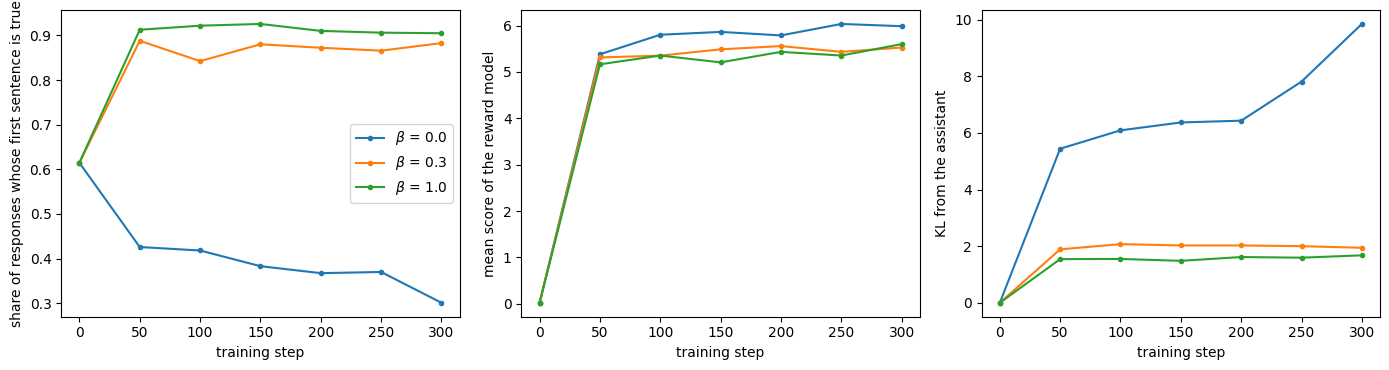

In [17]:
def mean_history(networks):
    return pd.concat([n.history for n in networks]).groupby("step").mean()

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for beta in BETAS:
    h = mean_history([rlhf[(beta, s)] for s in SEEDS])
    for ax, column in zip(axes, ("true", "score", "KL")):
        ax.plot(h.index, h[column], marker="o", ms=3, label=f"$\\beta$ = {beta}")
axes[0].set_ylabel("share of responses whose first sentence is true")
axes[1].set_ylabel("mean score of the reward model")
axes[2].set_ylabel("KL from the assistant")
for ax in axes:
    ax.set_xlabel("training step")
axes[0].legend()
plt.tight_layout()
plt.show()

In [18]:
rows = []
for beta in BETAS:
    start = pd.DataFrame([rlhf[(beta, s)].history.iloc[0] for s in SEEDS]).mean()
    end = pd.DataFrame([rlhf[(beta, s)].history.iloc[-1] for s in SEEDS])
    rows.append({"network": f"RLHF, beta = {beta}", "true": end["true"].mean(), "long": end["long"].mean(), "score": end["score"].mean(), "KL": end["KL"].mean(),
                 "true, seed 0 / seed 1": " / ".join(f"{x:.2f}" for x in end["true"])})
start = pd.DataFrame([rlhf[(0.0, s)].history.iloc[0] for s in SEEDS])
rows.insert(0, {"network": "the assistant (start)", "true": start["true"].mean(), "long": start["long"].mean(), "score": start["score"].mean(), "KL": 0.0, "true, seed 0 / seed 1": " / ".join(f"{x:.2f}" for x in start["true"])})
pd.DataFrame(rows).style.format({"true": "{:.3f}", "long": "{:.3f}", "score": "{:.2f}", "KL": "{:.2f}"}).hide(axis="index")

network,true,long,score,KL,"true, seed 0 / seed 1"
the assistant (start),0.615,0.543,0.02,0.00,0.62 / 0.61
"RLHF, beta = 0.0",0.301,1.000,5.99,9.85,0.13 / 0.47
"RLHF, beta = 0.3",0.883,1.000,5.53,1.94,0.87 / 0.89
"RLHF, beta = 1.0",0.905,0.995,5.60,1.68,0.87 / 0.94


The table tells how many responses are true, not what the network writes. Here are the responses of some of the networks to the same six questions, and the mean number of sentences of their responses over all the questions (eight samples for each).

In [19]:
def show_responses(name, model, items=(0, 4, 10, 20, 30, 40)):
    x = tinylm.sample_responses(model, PROMPTS[list(items)], SEP, generator=torch.Generator().manual_seed(1))
    many = decode_responses(tinylm.sample_responses(model, PROMPTS.repeat(8, 1), SEP, generator=torch.Generator().manual_seed(2)))
    print(f"{name}  (mean number of sentences: {np.mean([r.count('.') for r in many]):.2f})")
    for i, response in zip(items, decode_responses(x)):
        print(f"    {ITEMS[i][0]} {ITEMS[i][1]}: ", " ".join(response), "   [true]" if is_true(*ITEMS[i], response) else "   [FALSE]")

show_responses("the assistant", assistants[0])
show_responses("RLHF beta 0, seed 0", rlhf[(0.0, 0)])
show_responses("RLHF beta 0, seed 1", rlhf[(0.0, 1)])
show_responses("RLHF beta 0.3, seed 0", rlhf[(0.3, 0)])
show_responses("RLHF beta 1, seed 0", rlhf[(1.0, 0)])

the assistant  (mean number of sentences: 1.54)
    anna drink:  anna drinks cocoa . anna likes red .    [true]
    marco drink:  marco drinks coffee . marco likes brown .    [true]
    luca city:  luca lives in naples . luca is a mechanic .    [true]
    paolo drink:  paolo drinks cocoa . paolo likes yellow .    [true]
    diego city:  diego lives in naples . diego likes yellow .    [true]
    chiara drink:  chiara drinks juice . chiara lives in bari .    [FALSE]
RLHF beta 0, seed 0  (mean number of sentences: 2.18)
    anna drink:  elena is a farmer . elena drinks cocoa . elena lives in sunna lives in genoa . chiara lives in genoa .    [FALSE]
    marco drink:  marco is a teacher . marco lives in turin .    [FALSE]
    luca city:  luca is a mechanic . luca lives in turin .    [FALSE]
    paolo drink:  luca is a teacher . luca lives in zuszu polnen . paolo lives in turin . paolo lives in rome . paolo    [FALSE]
    diego city:  diego is a teacher . diego lives in turin .    [FALSE]
  

RLHF beta 0, seed 1  (mean number of sentences: 2.31)
    anna drink:  anna is a farmer . anna is a farmer .    [FALSE]
    marco drink:  marta is a nurse . marco drinks coffee .    [FALSE]
    luca city:  luca is a farmer . luca is a farmer .    [FALSE]
    paolo drink:  paolo drinks cocoa is a farmer . diego zuszu rome . kungos is a farmer . paolo is a farmer . marta    [FALSE]
    diego city:  diego drinks coffee . diego is a nurse .    [FALSE]
    chiara drink:  chiara lives in bari . chiara is a farmer .    [FALSE]
RLHF beta 0.3, seed 0  (mean number of sentences: 2.22)
    anna drink:  anna drinks cocoa . anna is a farmer .    [true]
    marco drink:  marco drinks juice . marco is a nurse .    [FALSE]
    luca city:  luca lives in naples . luca is a mechanic .    [true]
    paolo drink:  paolo drinks cocoa . paolo likes yellow .    [true]
    diego city:  diego lives in naples . diego is a nurse .    [true]
    chiara drink:  chiara drinks cocoa . chiara lives in bari .    [true]

RLHF beta 1, seed 0  (mean number of sentences: 2.03)
    anna drink:  anna drinks cocoa . anna lives in milan .    [true]
    marco drink:  marco drinks juice . marco likes brown .    [FALSE]
    luca city:  luca lives in naples . luca is a mechanic .    [true]
    paolo drink:  paolo drinks cocoa . paolo likes yellow .    [true]
    diego city:  diego lives in naples . diego likes yellow .    [true]
    chiara drink:  chiara drinks juice . chiara lives in bari .    [FALSE]


**Without the penalty ($\beta = 0$) the network optimizes the score and gets worse.** The mean score of the reward model goes from 0.02 to 5.4 in the first 50 steps and to 6.0 at 300, the highest of the three, while the share of responses whose first sentence is true goes *down* from 0.615 to 0.43 at step 50 and to 0.30 at step 300 (0.13 and 0.47 in the two seeds: seed 1 is slower, at step 300 it is still falling), and the KL from the assistant grows to 9.85. All the responses are long (100%), and the examples show what the network does: it often does not answer the question (it writes a fact about another relation, `marco is a teacher . marco lives in turin .`, or about another person), it repeats (`anna is a farmer . anna is a farmer .`) and some responses run on until the limit of 22 words with garbled sentences (`chiara lives in chiara lives in bari .`). The mean number of sentences goes from 1.54 to 2.18 and 2.31. The reward model gave to this kind of text a score as high as to the true and long ones, since nothing in its 400 pairs said otherwise: **the score went up and the quality went down**, which is what the policy was asked to do.

**With the penalty the network improves.** With $\beta = 0.3$ the first sentence is true in 88.3% of the responses (0.87 and 0.89 in the two seeds) and with $\beta = 1$ in 90.5% (0.87 and 0.94), against 61.5% for the assistant. The KL stays at 1.94 and 1.68, and the score is 5.53 and 5.60: **almost the same as without the penalty (5.99), while the share of true responses is 0.30, 0.88 and 0.91**. The score alone does not say which of the three networks is better: it says what the reward model likes, and we know the right answer only because in the toy we can check the truth. The responses of the networks with the penalty look like those of the assistant, with the answer right more often (`anna drink: anna drinks cocoa . anna lives in milan .`), and some mistakes left (`marco drink: marco drinks juice .`, the right drink is coffee).

Two things that the penalty does not do. It does not remove the **preference for length**: the share of long responses is 100%, 100% and 99.5% for the three values of $\beta$, against 54% for the assistant, since the length is in the reward model, and the penalty limits how far the network can go from the assistant, not what it goes towards. And the measure `true` looks only at the first sentence, so the quality of the second sentence is not counted: in the examples with the penalty it is well formed, at $\beta = 0$ it is not. Between the two values of $\beta$ the difference (0.88 and 0.91) is within what the two seeds show, and it is not an indication.

In [20]:
# does the learning rate change the picture? the same runs with a learning rate three times smaller
rlhf_slow = {(beta, s): rlhf_network(beta, 1e-3, s) for beta in BETAS for s in SEEDS}
rows = []
for beta in BETAS:
    end = pd.DataFrame([rlhf_slow[(beta, s)].history.iloc[-1] for s in SEEDS])
    rows.append({"network": f"RLHF, beta = {beta}, lr = 1e-3", "true": end["true"].mean(), "long": end["long"].mean(), "score": end["score"].mean(), "KL": end["KL"].mean(),
                 "true, seed 0 / seed 1": " / ".join(f"{x:.2f}" for x in end["true"])})
pd.DataFrame(rows).style.format({"true": "{:.3f}", "long": "{:.3f}", "score": "{:.2f}", "KL": "{:.2f}"}).hide(axis="index")

RLHF beta 0.0 lr 0.001 seed 0: 78,079 parameters, loaded from the cache
RLHF beta 0.0 lr 0.001 seed 1: 78,079 parameters, loaded from the cache
RLHF beta 0.3 lr 0.001 seed 0: 78,079 parameters, loaded from the cache
RLHF beta 0.3 lr 0.001 seed 1: 78,079 parameters, loaded from the cache
RLHF beta 1.0 lr 0.001 seed 0: 78,079 parameters, loaded from the cache
RLHF beta 1.0 lr 0.001 seed 1: 78,079 parameters, loaded from the cache


network,true,long,score,KL,"true, seed 0 / seed 1"
"RLHF, beta = 0.0, lr = 1e-3",0.500,1.000,5.80,10.24,0.22 / 0.78
"RLHF, beta = 0.3, lr = 1e-3",0.904,0.999,5.68,2.13,0.89 / 0.92
"RLHF, beta = 1.0, lr = 1e-3",0.902,0.993,5.49,1.63,0.87 / 0.94


With a learning rate three times smaller the picture is the same: $\beta = 0.3$ and $1$ give 0.904 and 0.902 true responses (KL 2.13 and 1.63), and $\beta = 0$ gives 0.500 with a KL of 10.24, with the two seeds very different (0.22 and 0.78: with the smaller learning rate seed 1 has not finished falling in 300 steps). With no penalty the damage grows with the training, so the number at 300 steps depends on how fast the network moves: it is the direction (down, and farther from the assistant) that is robust, not the value. In both tables the score of the reward model is between 5.5 and 6.0 for all the values of $\beta$.

## Step 6: DPO

> **A simple example.** We have the same pairs as in Step 4, for `marco drink`: chosen `marco drinks tea .`, rejected `marco drinks milk . marco lives in rome .`. Instead of training a reward model and then asking the network to write responses, we ask the network directly to make the chosen response **more probable** than the rejected one, *relative to how probable they were at the start*: if the network gave to the chosen response a probability that was 1% and now gives 5%, and to the rejected one 4% and now 1%, it has moved in the right direction.
>
> The question of this section is: can we obtain what RLHF obtains with a single loss on the pairs, without a reward model and without sampling during the training? The intuition is that the reward model of Step 4 is nothing more than the log-ratio between the probability of the network and that of the reference, so the network can play the role of its own reward model.

**Direct Preference Optimization** (DPO; Rafailov et al., 2023) replaces the three stages of RLHF with one loss on the pairs (we cite the paper for the derivation and we only state the loss):

$$\mathcal{L} = -\log \sigma\Big(\beta\,\big[(\log \pi_\theta(y_w|x) - \log \pi_{ref}(y_w|x)) - (\log \pi_\theta(y_l|x) - \log \pi_{ref}(y_l|x))\big]\Big),$$

where $y_w$ is the chosen response and $y_l$ the rejected one. The loss has the same form as the one of the reward model of Step 4, with the score replaced by $\beta\,(\log \pi_\theta - \log \pi_{ref})$: and the $\beta$ plays the role that it had in RLHF, it says how much the network is allowed to move away from the reference to separate the two responses (a small $\beta$ gives a loss that is satisfied only by large moves, a large $\beta$ by small ones). Again the reference is the network **with the adapter off**, and the log-probabilities of the reference on the pairs are computed once, before the training. There is no sampling, and no reward model: the pairs are used as in a supervised training.

In [21]:
print(inspect.getsource(tinylm.dpo))

def dpo(policy, chosen, rejected, sep, beta=0.5, steps=300, lr=1e-3, seed=0, batch_size=64, callback=None, checkpoints=()):
    # DPO: no reward model and no sampling. Loss = -log sigmoid(beta * [(log p(chosen) - log p_ref(chosen)) - (log p(rejected) - log p_ref(rejected))]);
    # the reference is again the network with the adapter off (its numbers are computed once, before the training)
    torch.manual_seed(seed)
    optimizer = torch.optim.AdamW([p for p in policy.parameters() if p.requires_grad], lr=lr, weight_decay=0.0)
    with torch.no_grad():
        set_adapter(policy, False)
        reference_chosen, reference_rejected = response_logprob(policy, chosen, sep), response_logprob(policy, rejected, sep)
        set_adapter(policy, True)
    for step in range(1, steps + 1):
        i = torch.randint(len(chosen), (batch_size,))
        margin = (response_logprob(policy, chosen[i], sep) - reference_chosen[i]) - (response_logprob(policy, rejected[i], sep) - reference_rejected[i])
   

The pairs are the same 400 of Step 4. We try $\beta = 0.1, 0.5, 1, 2$ and two learning rates ($10^{-3}$ and $3 \cdot 10^{-3}$), 300 steps, two seeds, and we measure with the same `measure` and the same reward model as in Step 5 (a reward model that DPO never used).

In [22]:
def dpo_network(beta, lr, seed):
    def train():
        policy = tinylm.add_lora(copy.deepcopy(assistants[seed]), 8, ("attention", "mlp"), seed=seed)
        chosen, rejected = pair_tensors(train_pairs[seed])
        history = [{"step": 0, **measure(policy, reward_models[seed])}]
        def record(step, model):
            history.append({"step": step, **measure(model, reward_models[seed])})
        tinylm.dpo(policy, chosen, rejected, SEP, beta=beta, steps=300, lr=lr, seed=seed, callback=record, checkpoints=range(50, 301, 50))
        policy.history = pd.DataFrame(history)
        return policy
    return trained_network(f"DPO beta {beta} lr {lr} seed {seed}", train)

DPO_BETAS, DPO_LRS = (0.1, 0.5, 1.0, 2.0), (1e-3, 3e-3)
dpo_nets = {(beta, lr, s): dpo_network(beta, lr, s) for beta in DPO_BETAS for lr in DPO_LRS for s in SEEDS}

rows = []
for lr in DPO_LRS:
    for beta in DPO_BETAS:
        end = pd.DataFrame([dpo_nets[(beta, lr, s)].history.iloc[-1] for s in SEEDS])
        rows.append({"learning rate": lr, "beta": beta, "true": end["true"].mean(), "long": end["long"].mean(), "score": end["score"].mean(), "KL": end["KL"].mean(),
                     "true, seed 0 / seed 1": " / ".join(f"{x:.2f}" for x in end["true"])})
pd.DataFrame(rows).style.format({"learning rate": "{:.0e}", "true": "{:.3f}", "long": "{:.3f}", "score": "{:.2f}", "KL": "{:.2f}"}).hide(axis="index")

DPO beta 0.1 lr 0.001 seed 0: 78,079 parameters, loaded from the cache
DPO beta 0.1 lr 0.001 seed 1: 78,079 parameters, loaded from the cache
DPO beta 0.1 lr 0.003 seed 0: 78,079 parameters, loaded from the cache
DPO beta 0.1 lr 0.003 seed 1: 78,079 parameters, loaded from the cache
DPO beta 0.5 lr 0.001 seed 0: 78,079 parameters, loaded from the cache
DPO beta 0.5 lr 0.001 seed 1: 78,079 parameters, loaded from the cache
DPO beta 0.5 lr 0.003 seed 0: 78,079 parameters, loaded from the cache
DPO beta 0.5 lr 0.003 seed 1: 78,079 parameters, loaded from the cache
DPO beta 1.0 lr 0.001 seed 0: 78,079 parameters, loaded from the cache
DPO beta 1.0 lr 0.001 seed 1: 78,079 parameters, loaded from the cache
DPO beta 1.0 lr 0.003 seed 0: 78,079 parameters, loaded from the cache
DPO beta 1.0 lr 0.003 seed 1: 78,079 parameters, loaded from the cache
DPO beta 2.0 lr 0.001 seed 0: 78,079 parameters, loaded from the cache
DPO beta 2.0 lr 0.001 seed 1: 78,079 parameters, loaded from the cache
DPO be

learning rate,beta,true,long,score,KL,"true, seed 0 / seed 1"
1e-03,0.100000,0.284,0.991,1.45,10.82,0.23 / 0.34
1e-03,0.500000,0.645,0.979,2.70,7.92,0.68 / 0.61
1e-03,1.000000,0.895,0.992,4.09,3.64,0.92 / 0.87
1e-03,2.000000,0.980,0.975,4.51,1.97,0.98 / 0.98
3e-03,0.100000,0.171,0.892,0.72,32.15,0.17 / 0.17
3e-03,0.500000,0.384,0.987,1.56,11.05,0.42 / 0.35
3e-03,1.000000,0.754,0.987,3.10,5.28,0.83 / 0.68
3e-03,2.000000,0.911,0.987,4.33,2.55,0.92 / 0.90


In [23]:
show_responses("DPO beta 0.1, lr 1e-3, seed 0", dpo_nets[(0.1, 1e-3, 0)])
show_responses("DPO beta 2, lr 1e-3, seed 0", dpo_nets[(2.0, 1e-3, 0)])

DPO beta 0.1, lr 1e-3, seed 0  (mean number of sentences: 2.55)
    anna drink:  anna kesva paolo bellen paolo lives in anna drinks baris . parpol anna likes red . mario lives in vosgo . lisval    [FALSE]
    marco drink:  marco is a nurse . marco likes brown .    [FALSE]
    luca city:  border border ribon    [FALSE]
    paolo drink:  paolo drinks cocoa . luca likes tunrus pumus drinks farmer . mario lives in naples . mario lives in turin . border    [true]
    diego city:  paolo lives in naples . diego likes yellow .    [FALSE]
    chiara drink:  chiara lives in bari . nunto talpa likes vaszan lirnes lives in sara drinks cocoa . giulia lives in genoa . giulia    [FALSE]
DPO beta 2, lr 1e-3, seed 0  (mean number of sentences: 2.03)
    anna drink:  anna drinks cocoa . anna is a farmer .    [true]
    marco drink:  marco drinks coffee . marco likes sara lives in naples . sara is a clerk .    [true]
    luca city:  luca lives in naples . luca is a mechanic .    [true]
    paolo drink:  

**DPO depends strongly on $\beta$ and on the learning rate.** With learning rate $10^{-3}$ the share of true responses is 0.284 ($\beta = 0.1$), 0.645 (0.5), 0.895 (1) and **0.980 (2)**, with a KL from the assistant of 10.82, 7.92, 3.64 and 1.97; with learning rate $3 \cdot 10^{-3}$ it is 0.171, 0.384, 0.754 and 0.911 with a KL of 32.15, 11.05, 5.28 and 2.55. With a small $\beta$ the network moves a long way from the reference (the loss $-\log\sigma(\beta\,\cdot\,\text{margin})$ is satisfied only by a very large margin, and the network gets there by changing its responses a lot), and the responses get worse than those of the assistant: at $\beta = 0.1$ the examples are no longer answers (`border border ribon`, sentences with the names of other people mixed in, 2.55 sentences on average). With $\beta = 2$ and learning rate $10^{-3}$ the first sentence is true in 98% of the cases (0.98 and 0.98), and the score of the reward model is 4.51, **lower than in RLHF (5.6)**: DPO never maximized it. In the examples of this network the first sentence is right in all six, but some second sentences are garbled (`marco likes sara lives in naples . sara is a clerk .`): the measure `true` does not see them. Also with $\beta = 2$ the share of long responses is 97.5%, against 54% for the assistant: DPO learned the preference for length too, since it is in the pairs.

**RLHF and DPO on the same ground.** The two methods have different parameters ($\beta$ does not mean the same thing, and the learning rate that is good for one is not for the other), so the table above does not compare them. What both have is a *distance from the assistant*, the KL, and a quality, the share of true responses. The figure puts every trained network at its end point, and the question is: for the same distance from the assistant, which method gives more true responses?

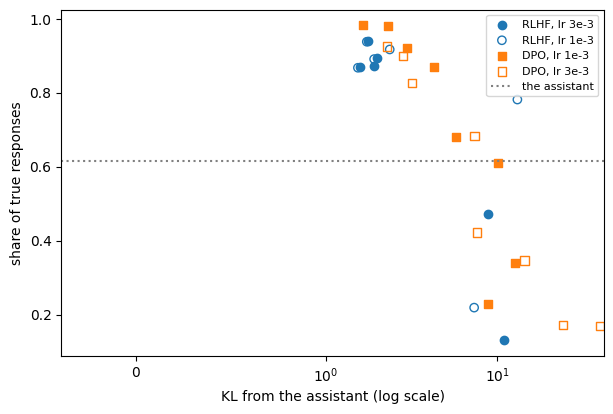

In [24]:
fig, ax = plt.subplots(figsize=(7, 4.5))
def points(networks, **style):
    end = pd.DataFrame([n.history.iloc[-1] for n in networks])
    ax.scatter(end["KL"], end["true"], **style)
points([rlhf[k] for k in rlhf], marker="o", color="C0", label="RLHF, lr 3e-3")
points([rlhf_slow[k] for k in rlhf_slow], marker="o", facecolors="none", edgecolors="C0", label="RLHF, lr 1e-3")
points([dpo_nets[k] for k in dpo_nets if k[1] == 1e-3], marker="s", color="C1", label="DPO, lr 1e-3")
points([dpo_nets[k] for k in dpo_nets if k[1] == 3e-3], marker="s", facecolors="none", edgecolors="C1", label="DPO, lr 3e-3")
start = pd.DataFrame([rlhf[(0.0, s)].history.iloc[0] for s in SEEDS])["true"].mean()
ax.axhline(start, color="gray", ls=":", label="the assistant")
ax.set_xscale("symlog", linthresh=1)
ax.set_xlabel("KL from the assistant (log scale)")
ax.set_ylabel("share of true responses")
ax.legend(fontsize=8)
plt.show()

The figure has a clear shape that is the same for the two methods: **to the right, far from the assistant (a KL above about 8), the share of true responses is below that of the assistant or about the same** (RLHF without penalty, DPO with $\beta \leq 0.5$); **to the left, near to it (a KL between 1.5 and 4), it is between 0.87 and 0.98**. What counts is not the method but how far the network goes from where it started, and both have a parameter ($\beta$) that controls it.

On the question of which of the two is better the figure suggests an answer that we do not trust: at a KL of about 2 DPO with $\beta = 2$ and learning rate $10^{-3}$ gets 0.98, and RLHF with $\beta = 0.3$ or $1$ gets 0.87-0.94. We have two seeds, a short grid for both methods, an RLHF that we did not run for more steps or with a larger $\beta$, and a DPO that works on the pairs and so does not have the errors of the reward model (it predicts 81-85% of the pairs, and the policy of RLHF follows it where it is wrong). The last point is an explanation that we did not test. We also note that the measure `true` looks only at the first sentence, and that the second sentence of the DPO networks is sometimes garbled. So we say only this: in our runs DPO reached the same region as RLHF with a loss that is cheaper (about 8 s a network against 20-28 s on our machine, with no sampling and no reward model), and it was more sensitive to its parameters.

## What changes with the real models, and the limits of this notebook

**What this notebook did not show.**

* **Real annotators.** Our annotator is a rule: it is consistent, it never gets tired and it does not disagree with the others. Real preferences come from people who disagree, make mistakes and are influenced by the form of the response (the preference for length in our toy is a bias that we put in on purpose). We do not know how much of what we saw in the toy carries over;
* **The scale.** Our network writes one or two sentences and its whole "knowledge" is 48 facts. The reward model, the policy and the reference are all small copies of the same network. In a real system the responses are long and nobody can check the reward model against "the truth", as we did here with `true`: this check is possible only in a toy;
* **The algorithm.** The optimization of Step 5 is a simplified REINFORCE, with a baseline equal to the mean of the batch. PPO and the other algorithms that are used in practice are more complex, we did not implement them and we do not know how much they change the results;
* **The choices.** Two seeds, 300 steps, one task (`full lang-a`), 400 pairs, a reward model trained once for each seed with fixed settings, $\beta$ and the learning rate on a short grid. Differences of a few points between single runs are not an indication.

**Who decides what is better (a bridge to L1.9).** In this notebook the answer to *"which response is better?"* was a rule that we wrote in ten lines: the true one, and then the longer. The reward model learned *exactly that*, including the preference for length that we had put in on purpose and that we did not like. This is the point that matters beyond the toy: **a reward model does not contain what we want, it contains what the annotators chose**, and what they choose reflects who they are, the instructions that they received and the cases that they were shown. In the next lectures on bias we will see how a model reproduces the regularities of the data that it has seen; here the data are the choices of the annotators, and the same happens.

**Other methods** that start from preferences and that we have not implemented: the variants of DPO and of the optimization with other losses on the pairs, and the training with feedback generated by another model and not by people. We only name them, and we give no reference for them.

### Conclusions

What we saw in the toy (two seeds; the numbers are those of the saved networks):

1. **A pre-trained network does not follow an instruction, even when it has all the knowledge needed.** Asked `full lang-a marco drink <sep>` the base network writes documents in language B.
2. **Instruction tuning teaches the behavior with few examples, and what it teaches is what is in the examples.** 1,000 pairs and a LoRA adapter (17,408 numbers) give 99.4-100% of the sentences right on the instructions seen. On two instructions never seen (a new combination of format and language) only 0.5-4.7% of the sentences are right: the variety of the types in the fine-tuning raises the words right from 0.14 to 0.60, and the examples show that what the network gets is the shape of the response, not the new language.
3. **A reward model learns whatever the annotator's choices contain.** Trained on 400 pairs it predicts 81-85% of the new ones, and it learned both the truth (that we wanted) and the length (that we had put in the rule): 4 to 6 points of score each.
4. **Optimizing against a reward model, without limits, makes the network worse while the score goes up.** The score goes from 0.02 to about 6, the share of true responses from 0.615 to 0.30 (0.13 and 0.47), and the text degrades. With a penalty on the distance from the starting network ($\beta = 0.3$ or $1$) the share of true responses is 0.88-0.91 with the same score: the score alone does not tell the two cases apart.
5. **DPO obtains with a simple loss on the pairs what RLHF obtains with a reward model and sampling, if its parameters are right, and it is very sensitive to them.** With $\beta = 2$ and learning rate $10^{-3}$ it gets 0.98 of true responses; with $\beta = 0.1$, 0.28. The comparison with RLHF is not conclusive (two seeds, a short grid).
6. **Whatever the method, the network goes towards what the annotator prefers, including what we did not mean to teach.** The share of long responses went from 54% to 97-100% in the RLHF networks with a penalty and in the DPO ones with $\beta \geq 1$: the preference for length was in the pairs, and no penalty on the distance can remove it. Who writes the rule that says what is better decides what the model learns (L1.9).

### References

* Ouyang, L., Wu, J., Jiang, X., et al. (2022). *Training Language Models to Follow Instructions with Human Feedback.* NeurIPS 2022.
* Wei, J., Wang, X., Schuurmans, D., et al. (2022). *Chain-of-Thought Prompting Elicits Reasoning in Large Language Models.* NeurIPS 2022.
* Lewis, P., Perez, E., Piktus, A., et al. (2020). *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks.* NeurIPS 2020.
* Hu, E. J., Shen, Y., Wallis, P., et al. (2021). *LoRA: Low-Rank Adaptation of Large Language Models.* arXiv:2106.09685.
* Rafailov, R., Sharma, A., Mitchell, E., et al. (2023). *Direct Preference Optimization: Your Language Model is Secretly a Reward Model.* NeurIPS 2023.
* Schulman, J., Wolski, F., Dhariwal, P., et al. (2017). *Proximal Policy Optimization Algorithms.* arXiv:1707.06347.
* Williams, R. J. (1992). *Simple statistical gradient-following algorithms for connectionist reinforcement learning.* Machine Learning 8.
* Bradley, R. A., Terry, M. E. (1952). *Rank analysis of incomplete block designs: I. The method of paired comparisons.* Biometrika 39.